# 5. A new setup with a few labeled surfaces

With no label a new setup does not work (`new_setup.ipynb`). Here we allow ourselves a short calibration:
somebody labels **k surfaces per family** on the new setup.

We use the vibration only. Each recording becomes one vector from BEATs, a pretrained audio model that we do
not train. On top we fit a small classifier.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FAMILIES = ["wood", "metal", "textile", "polymer"]

## The data

One BEATs vector per recording, made in `data.ipynb`. Cluster, LMT108 and SENS3 are our three development
setups. HaTT is the test we kept locked.

In [2]:
saved = np.load("cache/vibration_vectors.npz", allow_pickle=True)
vectors = saved["vectors"]
info = pd.DataFrame({c: saved[c] for c in ["dataset", "surface", "family"]})

info.groupby("dataset").agg(recordings=("family", "size"), surfaces=("surface", "nunique"))

,recordings,surfaces
dataset,,
cluster,2880,72
hatt,172,43
lmt108,720,36
sens3,2400,30


## The classifier

Standardize, keep at most 256 principal components, logistic regression.
Every (dataset, family) group gets the same total weight.

In [3]:
def train_and_test(train, test):
    part = info[train]
    weight = 1 / part.groupby(["dataset", "family"]).family.transform("size").to_numpy()
    model = make_pipeline(
        StandardScaler(), PCA(min(256, train.sum() - 1), random_state=0), LogisticRegression(max_iter=3000)
    )
    model.fit(vectors[train], part.family, logisticregression__sample_weight=weight / weight.mean())
    return model.predict(vectors[test])


def pick_surfaces(setup, k, rng):
    # k surfaces per family of this setup, at random
    surfaces = info[info.dataset == setup][["surface", "family"]].drop_duplicates()
    picked = [rng.choice(surfaces.surface[surfaces.family == f], k, replace=False) for f in FAMILIES]
    return info.surface.isin(np.concatenate(picked)).to_numpy()

## First on the development setups: alone, or with the other setups?

Each of the three setups plays the new one in turn. We compare two ways of training:

- only the k labeled surfaces of the new setup;
- the two other setups + the k labeled surfaces.

In [4]:
development = ["cluster", "lmt108", "sens3"]
rows = []
for number, setup in enumerate(development):
    new = (info.dataset == setup).to_numpy()
    others = info.dataset.isin(development).to_numpy() & ~new
    for k in [1, 2]:
        for draw in range(10):
            labeled = pick_surfaces(setup, k, np.random.default_rng([number, k, draw]))
            test = new & ~labeled
            for name, train in [("labels only", labeled), ("other setups + labels", others | labeled)]:
                score = balanced_accuracy_score(info.family[test], train_and_test(train, test))
                rows.append({"new setup": setup, "k": k, "training": name, "score": score})

development_scores = pd.DataFrame(rows).groupby(["training", "new setup", "k"]).score.mean().unstack("k")
development_scores.to_csv("results/few_labels_development.csv")
development_scores.round(2)

k                                   1     2
training              new setup            
labels only           cluster    0.48  0.52
                      lmt108     0.61  0.67
                      sens3      0.38  0.48
other setups + labels cluster    0.41  0.46
                      lmt108     0.38  0.54
                      sens3      0.36  0.44

The labels of the new setup alone do better than with the other setups added, on the three setups.
So we froze this choice (BEATs, labels of the new setup only) **before** looking at HaTT, and wrote the pass mark:
at least 0.45 with 2 surfaces per family.

## The locked test on HaTT

HaTT is a steel tip held by hand, from another lab. 43 surfaces, and only 3 of them are wood.

- k = 0: a classifier trained on the three development setups, no HaTT label.
- k = 1 and k = 2: only the labeled HaTT surfaces, 20 random draws.

The interval comes from drawing the test surfaces again, with replacement, 500 times.

In [5]:
def score_with_interval(test, predicted):
    right = (predicted == info.family[test]).groupby([info.family[test], info.surface[test]]).agg(["sum", "count"])
    recall = [right.loc[f, "sum"].sum() / right.loc[f, "count"].sum() for f in FAMILIES]
    rng = np.random.default_rng(42)
    draws = []
    for _ in range(500):
        again = []
        for f in FAMILIES:
            pick = rng.choice(len(right.loc[f]), len(right.loc[f]))
            again.append(right.loc[f, "sum"].to_numpy()[pick].sum() / right.loc[f, "count"].to_numpy()[pick].sum())
        draws.append(np.mean(again))
    return [np.mean(recall), np.percentile(draws, 2.5), np.percentile(draws, 97.5), *recall]


hatt = (info.dataset == "hatt").to_numpy()
rows = [[0, *score_with_interval(hatt, train_and_test(~hatt, hatt))]]
for k in [1, 2]:
    for draw in range(20):
        labeled = pick_surfaces("hatt", k, np.random.default_rng([99, k, draw]))
        test = hatt & ~labeled
        rows.append([k, *score_with_interval(test, train_and_test(labeled, test))])

locked = pd.DataFrame(rows, columns=["k", "score", "low", "high", *FAMILIES]).groupby("k").mean()
locked.to_csv("results/few_labels_locked_test.csv")
locked.round(2)

,score,low,high,wood,metal,textile,polymer
k,,,,,,,
0,0.42,0.32,0.52,0.83,0.40,0.34,0.10
1,0.53,0.44,0.63,0.99,0.44,0.51,0.19
2,0.64,0.54,0.76,1.00,0.63,0.61,0.33


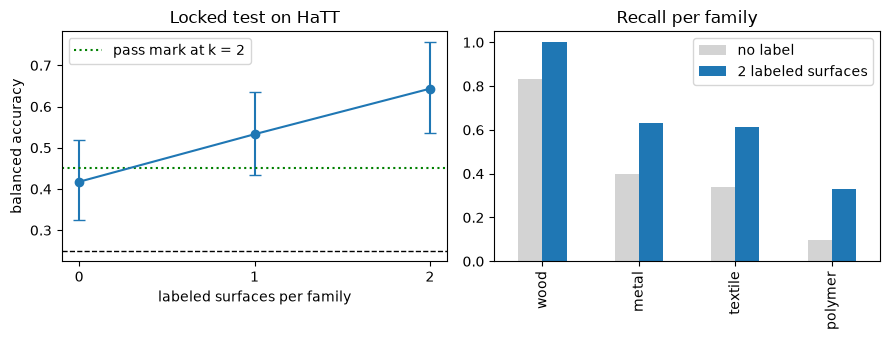

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].errorbar(locked.index, locked.score, [locked.score - locked.low, locked.high - locked.score], marker="o", capsize=4)
axes[0].axhline(0.25, color="black", linestyle="--", linewidth=1)
axes[0].axhline(0.45, color="green", linestyle=":", label="pass mark at k = 2")
axes[0].set_xticks([0, 1, 2])
axes[0].set_xlabel("labeled surfaces per family")
axes[0].set_ylabel("balanced accuracy")
axes[0].set_title("Locked test on HaTT")
axes[0].legend()
locked.loc[[0, 2], FAMILIES].T.plot.bar(ax=axes[1], color=["lightgrey", "tab:blue"])
axes[1].set_title("Recall per family")
axes[1].legend(["no label", "2 labeled surfaces"])
plt.tight_layout()
plt.savefig("results/few_labels_locked_test.png", dpi=120)

## Which surfaces should we label?

Above, the labeled surfaces were drawn at random. But we can look at the new setup before labeling anything: its
recordings have no label, but we can group them. Idea: group the surfaces with k-means into N groups, and label the
surface closest to the centre of each group (its "medoid"). The groups should cover the variety of the new setup
better than a random draw.

We compare three ways of choosing N surfaces to label:

- **medoids** of a k-means (no label needed to choose them);
- **random**: N surfaces at random;
- **per family**: N / 4 surfaces of each family, at random. This one cheats a bit: to choose, you must already know
  the families. It is the reference of the locked test above.

One vector per surface (the slide vibration, at 3 kHz, from `data.ipynb`), a logistic regression trained on the N
labeled surfaces only, tested on all the other surfaces. Repeated on 40 random subsets of 80 % of the surfaces.

In [7]:
from sklearn.cluster import KMeans

saved = np.load("cache/vibration_vectors_3khz.npz", allow_pickle=True)
slide = pd.DataFrame({c: saved[c] for c in ["dataset", "surface", "family"]})


def surfaces_of(dataset, table=slide, vectors=saved["vectors"]):
    # one mean vector per labeled surface of a dataset, and its family (TUM: no textile, it has only 4)
    rows = ((table.dataset == dataset) & (table.family != "")).to_numpy()
    if dataset == "TUM":
        rows = rows & (table.family != "textile").to_numpy()
    means = pd.DataFrame(vectors[rows]).groupby(table.surface[rows].to_numpy()).mean()
    family = table[rows].drop_duplicates("surface").set_index("surface").family.loc[means.index]
    return means, family


def probe_score(x, y, labeled):
    # trained on the labeled surfaces only, balanced accuracy on all the others (a family never labeled scores 0)
    test = np.setdiff1d(np.arange(len(y)), labeled)
    if len(np.unique(y[labeled])) < 2:
        answers = np.full(len(test), y[labeled][0])
    else:
        model = LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced").fit(x[labeled], y[labeled])
        answers = model.predict(x[test])
    return balanced_accuracy_score(y[test], answers)


def medoids(x, n, seed):
    groups = KMeans(n, n_init=4, random_state=seed).fit(x)
    distance = ((x[:, None] - groups.cluster_centers_[None]) ** 2).sum(-1)
    return np.unique(distance.argmin(axis=0))


def per_family(y, n, rng):
    k = max(1, n // len(np.unique(y)))
    return np.concatenate([rng.choice(np.flatnonzero(y == f), min(k, (y == f).sum() - 1), replace=False) for f in np.unique(y)])


def compare_choices(x, y, sizes, subsets=40, draws=20):
    rng = np.random.default_rng(0)
    rows = []
    for subset in range(subsets):
        keep = rng.choice(len(y), int(round(0.8 * len(y))), replace=False)
        xs, ys = x[keep], y[keep]
        xs = (xs - xs.mean(0)) / (xs.std(0) + 1e-6)
        z = PCA(min(20, len(ys) - 1), random_state=0).fit_transform(xs)
        for n in sizes:
            rows.append({"subset": subset, "N": n, "choice": "medoids", "score": probe_score(xs, ys, medoids(z, n, subset))})
            rows.append({"subset": subset, "N": n, "choice": "random",
                         "score": np.mean([probe_score(xs, ys, rng.choice(len(ys), n, replace=False)) for _ in range(draws)])})
            rows.append({"subset": subset, "N": n, "choice": "per family",
                         "score": np.mean([probe_score(xs, ys, per_family(ys, n, rng)) for _ in range(draws)])})
    return pd.DataFrame(rows)


rows = []
for dataset in ["HaTT", "LMT108", "TUM", "SENS3", "Cluster"]:
    means, family = surfaces_of(dataset)
    rows.append(compare_choices(means.to_numpy(), family.to_numpy(), [4, 8, 12, 16]).assign(dataset=dataset))
choices = pd.concat(rows)
choices.to_csv("results/few_labels_choosing_surfaces.csv", index=False)
choices.pivot_table(index=["dataset", "N"], columns="choice", values="score").round(2)

choice      medoids  per family  random
dataset N                              
Cluster 4      0.56        0.56    0.46
        8      0.59        0.63    0.55
        12     0.64        0.67    0.61
        16     0.68        0.69    0.64
HaTT    4      0.44        0.57    0.39
        8      0.67        0.66    0.51
        12     0.70        0.68    0.57
        16     0.73        0.69    0.62
LMT108  4      0.60        0.57    0.45
        8      0.72        0.67    0.58
        12     0.79        0.69    0.64
        16     0.81        0.70    0.67
SENS3   4      0.32        0.35    0.33
        8      0.35        0.43    0.39
        12     0.43        0.47    0.45
        16     0.44        0.48    0.48
TUM     4      0.61        0.56    0.47
        8      0.71        0.64    0.54
        12     0.72        0.70    0.59
        16     0.71        0.72    0.61

In [8]:
wide = choices.pivot_table(index=["dataset", "N", "subset"], columns="choice", values="score")
gain = (wide.medoids - wide.random).groupby(["dataset", "N"])
summary = pd.DataFrame({"medoids - random": gain.mean(), "low": gain.quantile(0.025), "high": gain.quantile(0.975)})
print("mean gain at N = 8:", round(summary.xs(8, level="N")["medoids - random"].mean(), 2))
summary.xs(8, level="N").round(2)

mean gain at N = 8: 0.09


,medoids - random,low,high
dataset,,,
Cluster,0.04,-0.04,0.12
HaTT,0.16,-0.03,0.29
LMT108,0.15,-0.02,0.28
SENS3,-0.05,-0.22,0.13
TUM,0.17,0.06,0.30


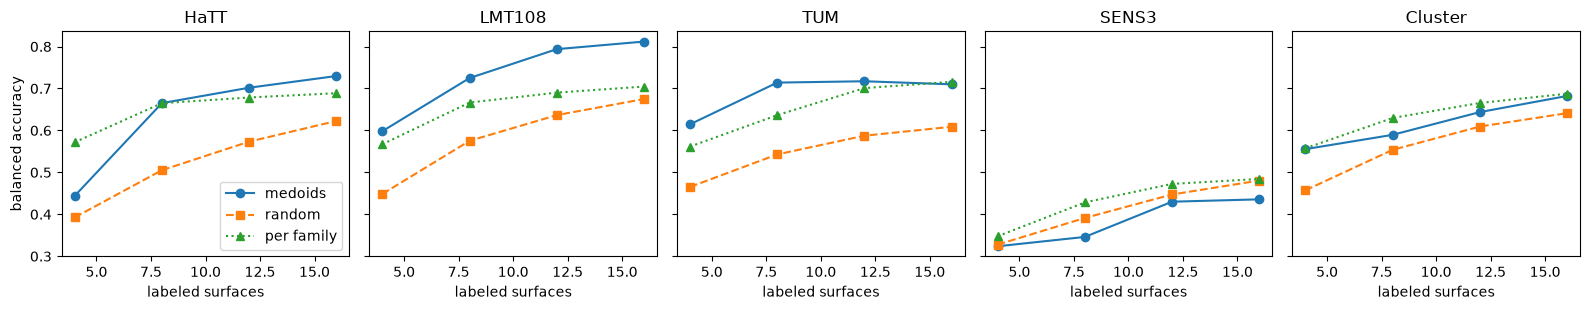

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), sharey=True)
mean = choices.groupby(["dataset", "N", "choice"]).score.mean().unstack("choice")
for ax, dataset in zip(axes, ["HaTT", "LMT108", "TUM", "SENS3", "Cluster"]):
    for choice, style in [("medoids", "o-"), ("random", "s--"), ("per family", "^:")]:
        ax.plot(mean.loc[dataset].index, mean.loc[dataset][choice], style, label=choice)
    ax.set_title(dataset)
    ax.set_xlabel("labeled surfaces")
axes[0].set_ylabel("balanced accuracy")
axes[0].legend()
plt.tight_layout()
plt.savefig("results/few_labels_choosing_surfaces.png", dpi=120)

## Adding taps

TUM and SENS3 also recorded each surface being tapped. A tap excites the object differently from a scrape: it tells
how hard and how resonant it is. Here we add the tap vectors to the scrape vectors, with k labeled surfaces per family
drawn at random (50 draws), and the same small classifier.

Each signal is standardized, then divided by the square root of its size, so the three signals weigh the same.

In [10]:
taps = np.load("cache/tap_vectors.npz", allow_pickle=True)
tap_table = pd.DataFrame({c: taps[c] for c in ["dataset", "surface", "signal"]})


def signals_of(dataset):
    slide_means, family = surfaces_of(dataset)
    blocks = {"scrape": slide_means}
    for name in ["tap vibration", "tap sound"]:
        rows = ((tap_table.dataset == dataset) & (tap_table.signal == name)).to_numpy()
        blocks[name] = pd.DataFrame(taps["vectors"][rows]).groupby(tap_table.surface[rows].to_numpy()).mean()
    common = family.index
    for block in blocks.values():
        common = common.intersection(block.index)
    scaled = {}
    for name, block in blocks.items():
        b = block.loc[common].to_numpy(float)
        scaled[name] = (b - b.mean(0)) / (b.std(0) + 1e-6) / np.sqrt(b.shape[1])
    return scaled, family.loc[common].to_numpy()


combinations = {
    "scrape": ["scrape"],
    "scrape + tap vibration": ["scrape", "tap vibration"],
    "scrape + tap vibration + tap sound": ["scrape", "tap vibration", "tap sound"],
}
rows = []
for dataset in ["TUM", "SENS3"]:
    blocks, y = signals_of(dataset)
    print(dataset, len(y), "surfaces with scrapes and taps", pd.Series(y).value_counts().to_dict())
    for name, parts in combinations.items():
        x = np.hstack([blocks[p] for p in parts])
        for k in [1, 2, 4]:
            for draw in range(50):
                labeled = np.concatenate([np.random.default_rng([k, draw, i]).choice(np.flatnonzero(y == f), min(k, (y == f).sum() - 1), replace=False)
                                          for i, f in enumerate(np.unique(y))])
                rows.append({"dataset": dataset, "signals": name, "k": k, "score": probe_score(x, y, labeled)})
with_taps = pd.DataFrame(rows)
with_taps.to_csv("results/few_labels_taps.csv", index=False)
with_taps.pivot_table(index=["dataset", "signals"], columns="k", values="score").round(2)

TUM 111 surfaces with scrapes and taps {'wood': 82, 'polymer': 18, 'metal': 11}


SENS3 30 surfaces with scrapes and taps {'textile': 12, 'polymer': 7, 'wood': 6, 'metal': 5}


k                                              1     2     4
dataset signals                                             
SENS3   scrape                              0.37  0.42  0.49
        scrape + tap vibration              0.55  0.66  0.72
        scrape + tap vibration + tap sound  0.55  0.66  0.75
TUM     scrape                              0.55  0.63  0.70
        scrape + tap vibration              0.58  0.66  0.73
        scrape + tap vibration + tap sound  0.61  0.69  0.74

## Both together

Medoids chosen on scrape + taps, against random, with 8 and 12 labeled surfaces.

In [11]:
rows = []
for dataset in ["TUM", "SENS3"]:
    blocks, y = signals_of(dataset)
    for name in ["scrape", "scrape + tap vibration + tap sound"]:
        x = np.hstack([blocks[p] for p in combinations[name]])
        rows.append(compare_choices(x, y, [8, 12], subsets=30).assign(dataset=dataset, signals=name))
both = pd.concat(rows)
both.to_csv("results/few_labels_medoids_and_taps.csv", index=False)
both.pivot_table(index=["dataset", "signals", "N"], columns="choice", values="score").round(2)

choice                                         medoids  per family  random
dataset signals                            N                              
SENS3   scrape                             8      0.36        0.43    0.40
                                           12     0.42        0.47    0.45
        scrape + tap vibration + tap sound 8      0.58        0.65    0.55
                                           12     0.65        0.70    0.62
TUM     scrape                             8      0.69        0.63    0.50
                                           12     0.70        0.69    0.56
        scrape + tap vibration + tap sound 8      0.64        0.69    0.48
                                           12     0.72        0.76    0.54

## What we see

- With 2 labeled surfaces per family: **0.64** on the locked test, above the 0.45 we had set. With no label: 0.42.
  This is the only locked test of the project that passed.
- Adding the other setups does not help. We find the same thing with CLAP in `fine_tuning.ipynb`.
- Polymer stays the weak family (0.33). Be careful with wood: only one wood surface is left to test at k = 2.
- Choosing the surfaces to label with k-means medoids helps on most datasets, without knowing the families: it does
  about as well as "2 per family", which needs them. It does not help on SENS3.
- Taps help when they are added to the scrapes, more on the bare finger (SENS3) than with the steel tool (TUM).
- None of this last part (medoids, taps) was tested on a locked setup.